# Poster / paper figures — line-cutting model (July 2026)

One notebook, two scopes:

- **`SCOPE = 'poster'`** — the frozen-config grid only (D7): L0, L1h, L2h, real L1 (fixed), real L2. The figures that go on the poster / in the paper.
- **`SCOPE = 'debug'`** — adds the historical arms (old May runs, ghost/zap variants, legacy real L1) for before/after comparisons. Same pipeline, wider RUNS dict.

**Swap-in points** (marked `# SWAP` below):
1. When `realL2_fixed` finishes on the cluster: flatten it, change one string.
2. When n=10 extensions land: re-run `flatten_array_runs.py`, set `recompute=True` once — everything downstream picks up the extra runs automatically.

Required data (relative to `analysis/`): `../data/simulations/*_flat`, `../data/scenarios/{scenario_lookup.csv, outcome_metrics.csv, completion_times.csv}`, `../data/experimental/{joe_univ_agg.csv, joe_univ_long.csv, joe_moral_agg.csv, joe_moral_long.csv, cross-cultrual-ind-trials.csv}`.

In [12]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from new_comparison_utils import (load_experiments, load_simulations, load_outcome_metrics,
    build_all_design_matrices, evaluate_fits, evaluate_fits_multi, split_half_all)
from bootstrap_significance import (bootstrap_over_participants, bootstrap_delta_r2,
    bootstrap_pairwise, pairwise_comparison_table)
from paper_figures import (fig_level_depth_grid, fig_bootstrap_ci, fig_multi_experiment_bars,
    fig_model_vs_humans, fig_model_vs_model, fig_compute_time)
from logan_individual import load_logan_individual
import fast_bootstrap; fast_bootstrap.install()   # 1000x on Logan bootstraps

SCOPE = 'poster'          # 'poster' | 'debug'

POSTER_RUNS = {
    'L0':            'L0_ghost_flat',
    'L1 heuristic':  'L1h_ghost_flat',
    'L2 heuristic':  'L2h_ghost_flat',
    'real L1':       'realL1_fixed_flat',
    'real L2':       'realL2_fixed_flat',
}
DEBUG_EXTRA = {
    'L1h (old May)':      'depth1_main5_cluster',
    'real L1 (legacy)':   'realL1_ghost_flat',
    'real L1 (old May)':  'depth2_v3_main5_cluster',
    'real L2 (old May)' :       'real_L2_merged',   # SWAP -> 'realL2_fixed_flat' when it lands
    'L0 (old May)':       'depth0_cluster',
    'L1h (zap)':          'L1h_fixedorder_zap_flat',
}
RUNS = dict(POSTER_RUNS, **(DEBUG_EXTRA if SCOPE == 'debug' else {}))

COLORS = {'L0':'#CC4444','L1 heuristic':'#2266CC','L2 heuristic':'#7799DD',
          'real L1':'#2E8B57','real L2':'#66BB88'}
ORDER  = ['L0','L1 heuristic','L2 heuristic','real L1','real L2']

fast_bootstrap installed: _resample_means vectorized (cached participant x stimulus matrix).


## 1. Load everything

In [14]:
datasets = load_experiments(joe_moral_agg='joe_moral_agg.csv', joe_moral_long='joe_moral_long.csv',
                            joe_univ_agg='joe_univ_agg.csv', joe_univ_long='joe_univ_long.csv')
# Logan INDIVIDUAL trials (new, July 2026): replaces the aggregated file and
# unlocks bootstrap CIs + per-country analysis on the cross-cultural data.
logan_pooled, logan_by_country = load_logan_individual()
datasets['logan_moral'] = logan_pooled

sims  = load_simulations(RUNS, recompute=True)     # recompute=True after new runs land
out_df = load_outcome_metrics()
dm = {k: build_all_design_matrices(sims, out_df, v) for k, v in datasets.items()}

ceilings = split_half_all(datasets)                 # noise ceilings per experiment
ceilings

Processed 28 maps for run_label='L0_ghost_flat' and saved to ../data/simulations/L0_ghost_flat/processed
Built universalization summary for run_label='L0_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  Excluded 2/140 stuck runs (1.4%)
  L0                    28 maps, 5 runs  mean U_AW=-3.502  stuck=2/140 (1.4%)
Processed 28 maps for run_label='L1h_ghost_flat' and saved to ../data/simulations/L1h_ghost_flat/processed
Built universalization summary for run_label='L1h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L1 heuristic          28 maps, 5 runs  mean U_AW=-1.142  stuck=0/140 (0.0%)
Processed 28 maps for run_label='L2h_ghost_flat' and saved to ../data/simulations/L2h_ghost_flat/processed
Built universalization summary for run_label='L2h_ghost_flat' over 28 maps and saved to summary_universalization_metrics.csv
  L2 heuristic          28 maps, 5 runs  mean U_AW=-1.265  stuck=0/140 (0.0%)
Processed 28 maps for run_label='realL

,name,n_participants,n_stimuli,r_half,ci_lo,ci_hi,spearman_brown,noise_ceiling
0,"Logan moral (pooled, ind)",1924,40,0.9929,0.9893,0.9958,0.9964,0.9982
1,Joe moral,39,39,0.9680,0.9431,0.9825,0.9837,0.9918
2,Joe univ,43,39,0.9615,0.9321,0.9800,0.9804,0.9901


## 2. The fits table (all experiments) and the grid

In [15]:
ev_univ  = evaluate_fits(dm['joe_univ'],  datasets['joe_univ'])
ev_moral = evaluate_fits(dm['joe_moral'], datasets['joe_moral'])
ev_logan = evaluate_fits(dm['logan_moral'], datasets['logan_moral'])
ev_univ[['tag','n','r_U_AW','delta_R2','p_U_AW']].round(3)

,tag,n,r_U_AW,delta_R2,p_U_AW
0,L1 heuristic,39,0.844,0.391,0.000
1,L2 heuristic,39,0.849,0.384,0.000
2,real L1,39,0.821,0.363,0.000
3,real L2,39,0.823,0.345,0.000
4,L0,39,0.587,0.101,0.013


Saved to figures/poster_grid_univ.png


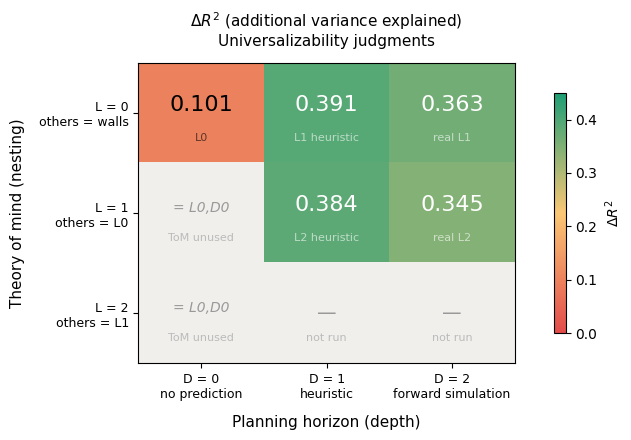

Saved to figures/poster_multi_exp.png


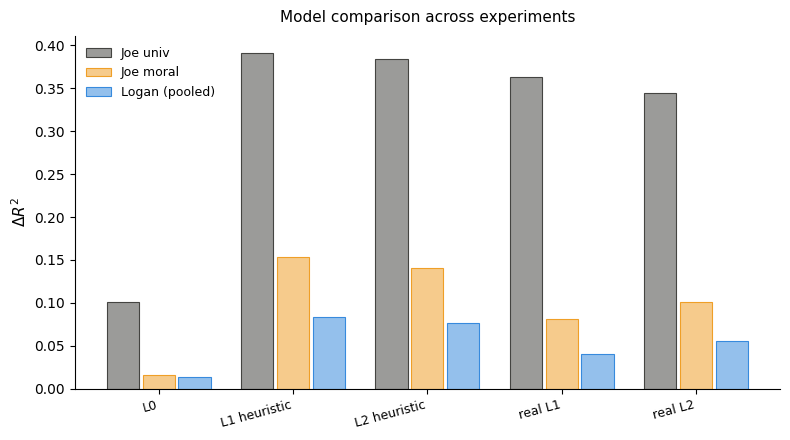

In [19]:
my_grid_map = {
    'L0':                         (0, 0),
    'L1 heuristic':               (0, 1),
    'real L1':       (0, 2),
    'L2 heuristic': (1,1),
    'real L2':               (1, 2),
}

fig_level_depth_grid(ev_univ, metric='delta_R2', grid_map=my_grid_map,
    title_suffix='Universalizability judgments',
    save_path='figures/poster_grid_univ.png')
fig_multi_experiment_bars({'Joe univ': ev_univ, 'Joe moral': ev_moral, 'Logan (pooled)': ev_logan},
    metric='delta_R2', model_order=ORDER, colors=COLORS,
    save_path='figures/poster_multi_exp.png')

## 3. THE main figure: bootstrap ΔR² over participants + the pairwise verdict

In [ ]:
ci_r_univ, boot_r_univ = bootstrap_over_participants(dm['joe_univ'], datasets['joe_univ'], n_boot=1000)
fig_bootstrap_ci(boot_univ, model_order=ORDER, colors=COLORS,
    ceiling=ceilings.loc[ceilings.experiment=='Joe univ','r_mean'].iloc[0]**2 if 'experiment' in ceilings else None,
    xlabel='$\\Delta R^2$ (additional variance explained)',
    title='Universalizability judgments — bootstrap over participants',
    save_path='figures/poster_boot_dr2_univ.png')
ci_univ.round(3)

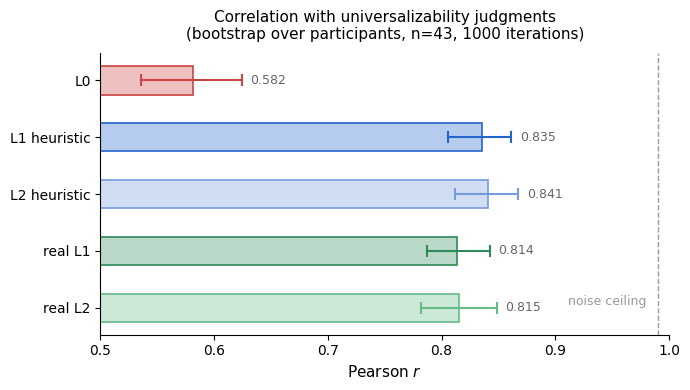

In [25]:

ci_r_univ, boot_r_univ = bootstrap_over_participants(dm["joe_univ"], datasets["joe_univ"], n_boot=1000)
fig_bootstrap_ci(boot_r_univ, model_order=ORDER, colors=COLORS,
    xlabel='Pearson $r$',
    title='Correlation with universalizability judgments\n(bootstrap over participants, n=43, 1000 iterations)',  
    xlim=(0.5, 1.0), ceiling=0.9901,)
    #save_path="figures/slide_2.png")

Saved to figures/poster_boot_dr2_univ.png


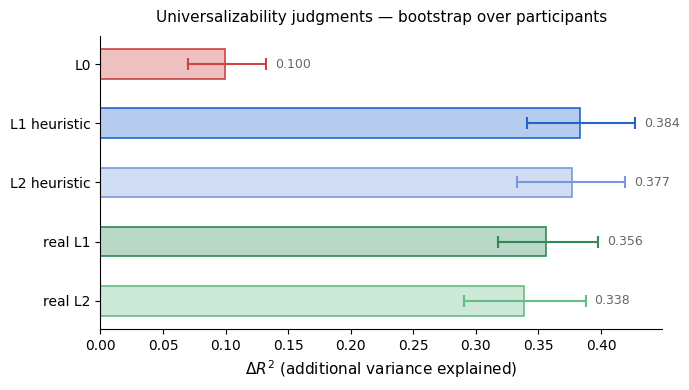

,tag,dr2_mean,dr2_median,dr2_ci_lo,dr2_ci_hi,dr2_se,r_mean,r_ci_lo,r_ci_hi
0,L0,0.100,0.100,0.070,0.132,0.016,0.582,0.536,0.624
1,L1 heuristic,0.384,0.384,0.341,0.427,0.022,0.835,0.805,0.861
2,L2 heuristic,0.377,0.377,0.333,0.419,0.022,0.841,0.812,0.868
3,real L1,0.356,0.355,0.318,0.398,0.021,0.814,0.787,0.842
4,real L2,0.338,0.339,0.291,0.388,0.024,0.815,0.782,0.848


In [20]:
ci_univ, boot_univ = bootstrap_delta_r2(dm['joe_univ'], datasets['joe_univ'], n_boot=1000)
fig_bootstrap_ci(boot_univ, model_order=ORDER, colors=COLORS,
    ceiling=ceilings.loc[ceilings.experiment=='Joe univ','r_mean'].iloc[0]**2 if 'experiment' in ceilings else None,
    xlabel='$\\Delta R^2$ (additional variance explained)',
    title='Universalizability judgments — bootstrap over participants',
    save_path='figures/poster_boot_dr2_univ.png')
ci_univ.round(3)

In [21]:
# The verdict sentence, on all three datasets:
for key in ['joe_univ', 'joe_moral', 'logan_moral']:
    res = bootstrap_pairwise(dm[key], datasets[key], 'L1 heuristic', 'real L1',
                             metric='delta_r2', n_boot=1000)
    print(f"{key:12s}  L1h - realL1: ΔΔR² = {res['diff_mean']:+.4f} "
          f"[{res['ci_lo']:+.4f}, {res['ci_hi']:+.4f}]  p = {res['p_value']:.4f}")

joe_univ      L1h - realL1: ΔΔR² = +0.0273 [+0.0023, +0.0522]  p = 0.0170
joe_moral     L1h - realL1: ΔΔR² = +0.0711 [+0.0517, +0.0908]  p = 0.0000
logan_moral   L1h - realL1: ΔΔR² = +0.0439 [+0.0375, +0.0502]  p = 0.0000


## 4. Models vs humans (scatter panel) and model vs model

Saved to figures/poster_model_vs_humans.png


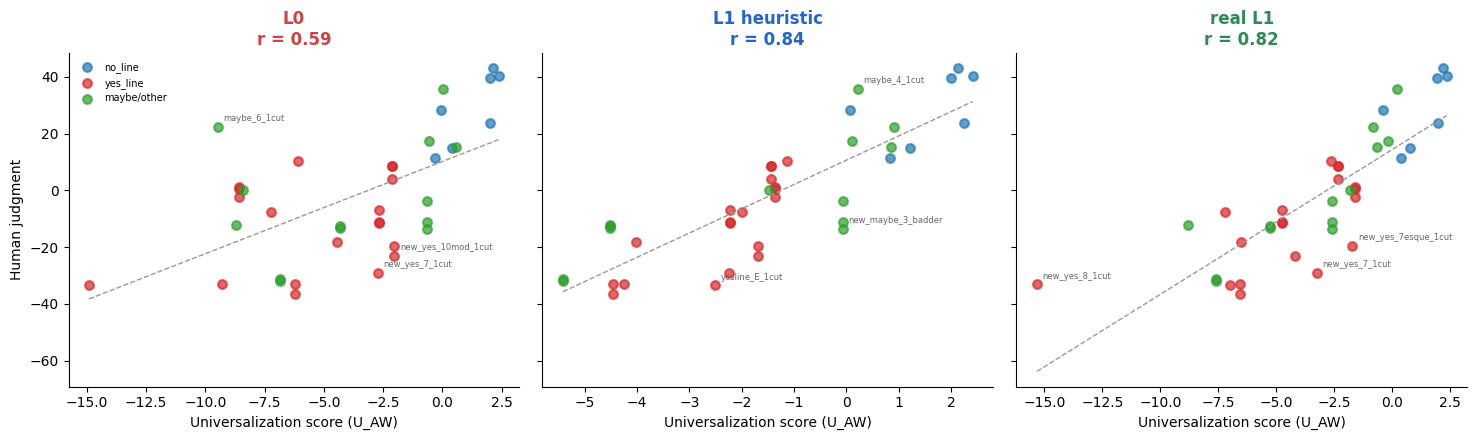

Saved to figures/poster_L1h_vs_realL1.png


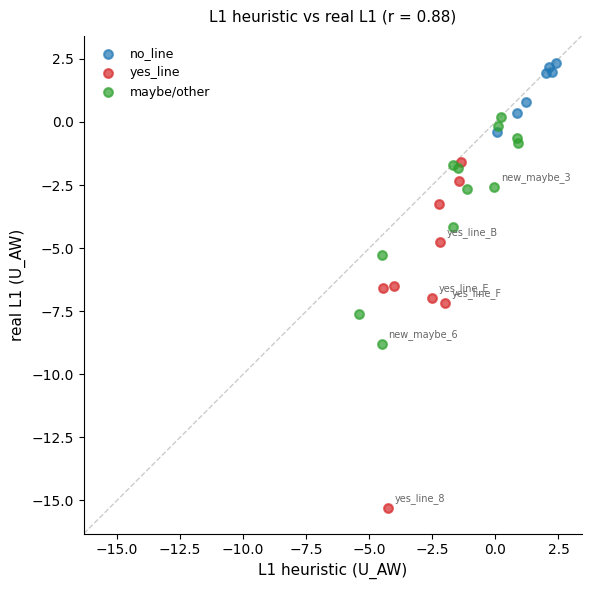

In [22]:
fig_model_vs_humans(dm['joe_univ'], datasets['joe_univ'],
    tags=['L0','L1 heuristic','real L1'], colors=COLORS,
    save_path='figures/poster_model_vs_humans.png')
fig_model_vs_model(sims, 'L1 heuristic', 'real L1', save_path='figures/poster_L1h_vs_realL1.png')

## 5. Resource-rationality: fit vs compute

Compute = mean `run_elapsed_seconds` per map (cold cache, 1 thread, one cell per
(map,run) — comparable across models by design, D4). Caveat D6: wall-clock is a
proxy; mechanism counts are the paper-grade measure.

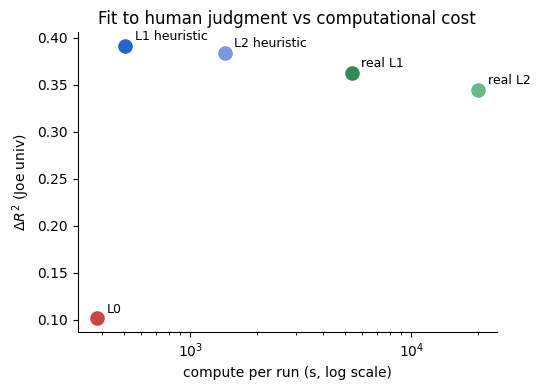

In [23]:
import glob
def mean_cost_per_map(label, sim_root='../data/simulations'):
    fs = glob.glob(f'{sim_root}/{label}/raw/*.csv')
    return pd.concat([pd.read_csv(f) for f in fs])['run_elapsed_seconds'].mean()

cost = {tag: mean_cost_per_map(lab) for tag, lab in RUNS.items() if tag in ORDER}
fit  = ev_univ.set_index('tag')['delta_R2']

fig, ax = plt.subplots(figsize=(5.5,4))
for tag in ORDER:
    if tag not in cost: continue
    ax.scatter(cost[tag], fit[tag], s=90, color=COLORS[tag], zorder=3)
    ax.annotate(tag, (cost[tag], fit[tag]), xytext=(7,4), textcoords='offset points', fontsize=9)
ax.set_xscale('log')
ax.set_xlabel('compute per run (s, log scale)'); ax.set_ylabel('$\\Delta R^2$ (Joe univ)')
ax.set_title('Fit to human judgment vs computational cost')
ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('figures/poster_fit_vs_compute.png', dpi=200)

## 6. Cross-cultural generalization (NEW — Logan individual data)

Per-country fit of the two focal models, bootstrap CIs over that country's
participants. The "this generalizes" figure.

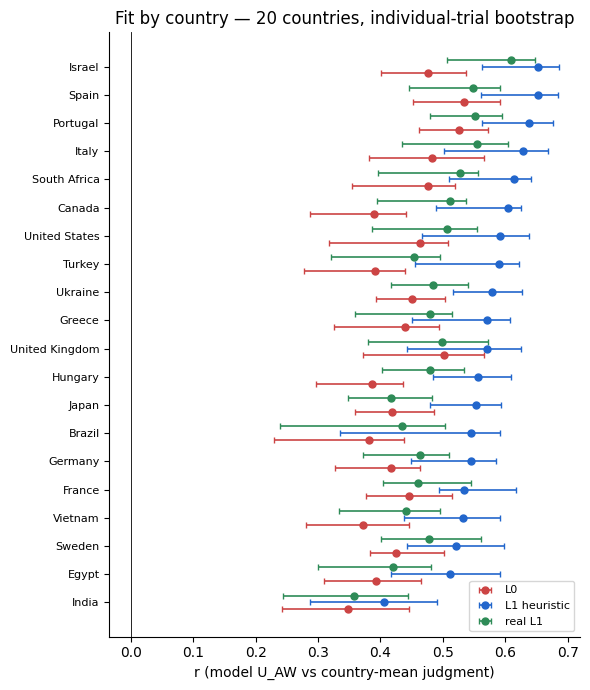

In [10]:
FOCAL = ['L0', 'L1 heuristic', 'real L1']
rows = []
for c, exp in sorted(logan_by_country.items()):
    dmc = build_all_design_matrices({t: sims[t] for t in FOCAL}, out_df, exp)
    ev  = evaluate_fits(dmc, exp)
    try:
        summ, _ = bootstrap_over_participants(dmc, exp, n_boot=1000)
        summ = summ.set_index('tag')
        for t in FOCAL:
            rows.append(dict(country=c, tag=t, r=ev.set_index('tag').loc[t,'r_U_AW'],
                             lo=summ.loc[t,'ci_lo'], hi=summ.loc[t,'ci_hi'],
                             n=exp.long_df['participant_id'].nunique()))
    except Exception as e:
        print(c, 'bootstrap failed:', e)
cc = pd.DataFrame(rows)
cc.to_csv('figures/poster_crosscultural_fits.csv', index=False)

order_c = cc[cc.tag=='L1 heuristic'].sort_values('r')['country']
fig, ax = plt.subplots(figsize=(6, 7))
for i, t in enumerate(FOCAL):
    sub = cc[cc.tag==t].set_index('country').loc[order_c]
    y = np.arange(len(sub)) + (i-1)*0.24
    ax.errorbar(sub['r'], y, xerr=[sub['r']-sub['lo'], sub['hi']-sub['r']],
                fmt='o', ms=5, color=COLORS[t], label=t, lw=1.2, capsize=2)
ax.set_yticks(np.arange(len(order_c))); ax.set_yticklabels(order_c, fontsize=8)
ax.axvline(0, color='k', lw=.6)
ax.set_xlabel('r (model U_AW vs country-mean judgment)')
ax.set_title('Fit by country — 20 countries, individual-trial bootstrap')
ax.legend(loc='lower right', fontsize=8); ax.spines[['top','right']].set_visible(False)
plt.tight_layout(); plt.savefig('figures/poster_by_country.png', dpi=200)

## 7. Robustness footnotes

- Stuck runs (frozen config): L0 2/140, all other poster models 0/140. Report; excluded from means.
- Rank robustness: Spearman alongside Pearson under TIME_MAX rescoring (L0 only).
- Ghost-vs-zap: L1h fit invariant (debug scope, 'L1h (zap)').
- Wave-2: softmax noise (T=0.05) cannot substitute for ghost jitter (finding #18).

In [11]:
from scipy.stats import spearmanr
d = dm['joe_univ']['L1 heuristic']
print('L1h  Pearson r=%.3f  Spearman rho=%.3f' % (
    np.corrcoef(d['univ_aggregate_welfare'], d[datasets['joe_univ'].dv_col])[0,1],
    spearmanr(d['univ_aggregate_welfare'], d[datasets['joe_univ'].dv_col])[0]))

L1h  Pearson r=0.844  Spearman rho=0.867
